<a href="https://colab.research.google.com/github/HarithaGottumukkala/DATA266-1598_hw8/blob/main/DATA266_HW8_1598.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Homework 8: Mini Diffusion Model (DDPM → DDIM)

## Introduction

In this homework, I am implementing a small diffusion model using the MNIST handwritten digit dataset.

The main idea is to understand how a diffusion model works in two directions. First, I will add random noise to the original images. Then, I will train a CNN to predict the noise so that I can generate new images using the reverse process.

After training, I will use DDPM and DDIM sampling to generate handwritten digits and compare how the results change when I use fewer sampling steps.

## Configuration

- **Dataset:** MNIST
- **Diffusion steps:** 100
- **Beta schedule:** Linear from 0.0001 to 0.02
- **Batch size:** 128
- **Epochs:** 50
- **Framework:** PyTorch

In [1]:

import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

import numpy as np
import matplotlib.pyplot as plt
import random

# Keeping the results reproducible
seed = 42
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(seed)

# Use GPU when it is available
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("PyTorch version:", torch.__version__)
print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


PyTorch version: 2.11.0+cu130
Device: cuda
GPU: Tesla T4


## Loading the MNIST Dataset

I am using the MNIST dataset for this experiment. It contains grayscale handwritten digit images, and each image has a size of 28 × 28 pixels.

Before training, I will convert the images into tensors and normalize their values between -1 and 1. I will also display a few images to check that the dataset was loaded correctly.

In [2]:

# Convert images into tensors and normalize them
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

train_dataset = datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_dataset = datasets.MNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

batch_size = 128

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True
)

print("Training images:", len(train_dataset))
print("Testing images:", len(test_dataset))

images, labels = next(iter(train_loader))
print("Batch shape:", images.shape)


100%|██████████| 9.91M/9.91M [00:00<00:00, 18.4MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 497kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.55MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 15.8MB/s]

Training images: 60000
Testing images: 10000
Batch shape: torch.Size([128, 1, 28, 28])


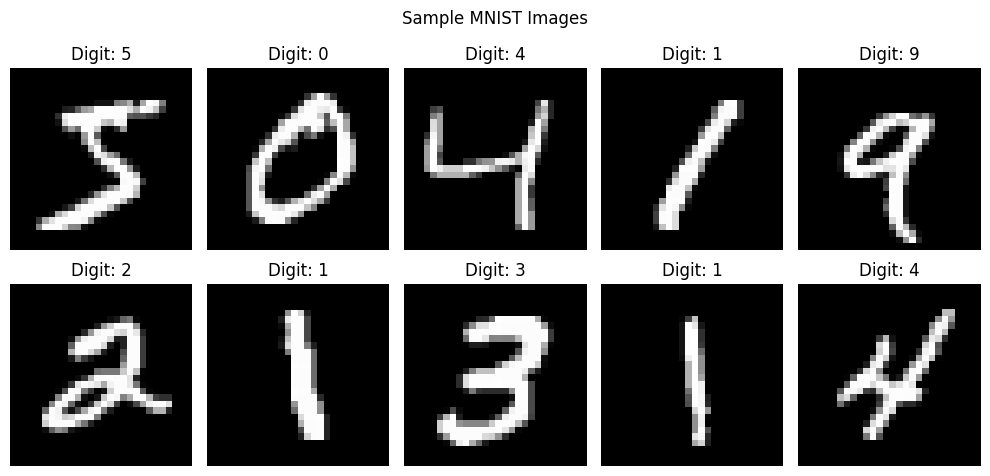

In [3]:

# Display a few images from MNIST
fig, axes = plt.subplots(2, 5, figsize=(10, 5))

for i, ax in enumerate(axes.flat):
    image, label = train_dataset[i]

    ax.imshow(image.squeeze(), cmap="gray")
    ax.set_title(f"Digit: {label}")
    ax.axis("off")

plt.suptitle("Sample MNIST Images")
plt.tight_layout()
plt.show()


## Part A: Forward Diffusion

In this part, I will take one MNIST image and gradually add Gaussian noise to it.

I am using 100 diffusion steps with beta values increasing linearly from 0.0001 to 0.02. I will use the forward diffusion equation to add noise and display the same image at different timesteps.

This will help me understand how the image changes as more noise is added.

In [4]:

# Diffusion settings
T = 100

# Linear beta schedule
betas = torch.linspace(0.0001, 0.02, T, device=device)

alphas = 1.0 - betas
alpha_bars = torch.cumprod(alphas, dim=0)

print("Diffusion steps:", T)
print("Beta shape:", betas.shape)
print("Alpha bar shape:", alpha_bars.shape)
print("First beta:", round(betas[0].item(), 6))
print("Last beta:", round(betas[-1].item(), 6))


Diffusion steps: 100
Beta shape: torch.Size([100])
Alpha bar shape: torch.Size([100])
First beta: 0.0001
Last beta: 0.02


In [5]:

def forward_diffusion(x0, t, noise=None):
    # Generate random Gaussian noise
    if noise is None:
        noise = torch.randn_like(x0)

    # Get alpha_bar for the selected timesteps
    alpha_bar_t = alpha_bars[t].view(-1, 1, 1, 1)

    # Add noise to the original image
    xt = (
        torch.sqrt(alpha_bar_t) * x0
        + torch.sqrt(1 - alpha_bar_t) * noise
    )

    return xt, noise


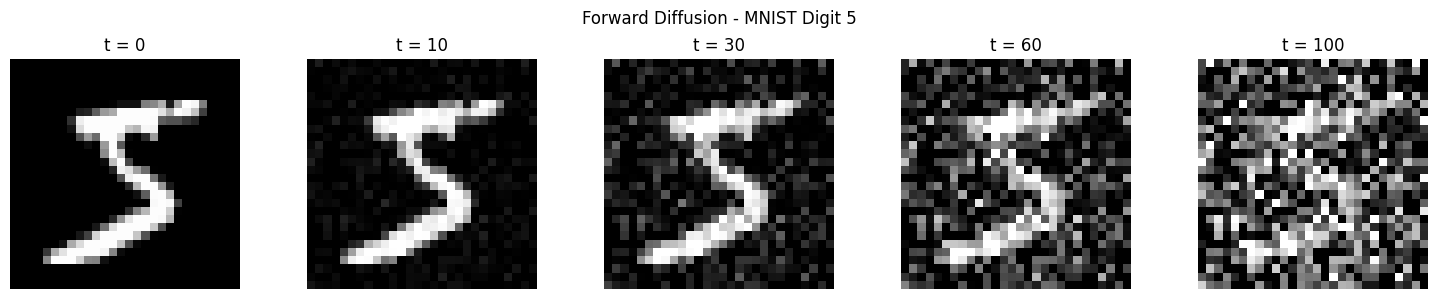

In [6]:

# Select one MNIST image
original_image, label = train_dataset[0]
original_image = original_image.unsqueeze(0).to(device)

# Timesteps requested in the assignment
timesteps = [0, 10, 30, 60, 100]

# Use the same noise to compare the changes clearly
fixed_noise = torch.randn_like(original_image)

fig, axes = plt.subplots(1, 5, figsize=(15, 3))

for i, step in enumerate(timesteps):

    if step == 0:
        noisy_image = original_image
    else:
        # Python schedule indices run from 0 to 99
        t = torch.tensor([step - 1], device=device)

        noisy_image, _ = forward_diffusion(
            original_image, t, fixed_noise
        )

    axes[i].imshow(
        noisy_image.squeeze().cpu().numpy(),
        cmap="gray",
        vmin=-1,
        vmax=1
    )
    axes[i].set_title(f"t = {step}")
    axes[i].axis("off")

plt.suptitle(f"Forward Diffusion - MNIST Digit {label}")
plt.tight_layout()
plt.show()


### Observation

From the visualization, I can see that the original digit is clear at timestep 0. As the timestep increases, the image becomes noisier and the digit starts losing its clarity.

At timestep 100, the noise is much stronger, but some parts of the original digit may still be visible. This shows how the forward diffusion process gradually adds noise to an image.

## Part B: Training a Mini DDPM

In this part, I am building a small CNN to predict the noise added to MNIST images.

The model will take a noisy image and its timestep as inputs. I am using convolutional layers with ReLU activations, and the output will have the same shape as the input image.

During training, I will compare the predicted noise with the actual Gaussian noise using Mean Squared Error (MSE) loss.

In [7]:

class NoisePredictor(nn.Module):
    def __init__(self, T=100):
        super().__init__()

        # Learn a representation for each timestep
        self.time_embedding = nn.Embedding(T, 32)

        # CNN to predict the noise
        self.conv1 = nn.Conv2d(33, 64, 3, padding=1)
        self.conv2 = nn.Conv2d(64, 64, 3, padding=1)
        self.conv3 = nn.Conv2d(64, 128, 3, padding=1)
        self.conv4 = nn.Conv2d(128, 128, 3, padding=1)
        self.conv5 = nn.Conv2d(128, 64, 3, padding=1)
        self.conv6 = nn.Conv2d(64, 1, 3, padding=1)

    def forward(self, x, t):
        # Convert timestep into a learned embedding
        time_emb = self.time_embedding(t)

        # Expand it to match the image height and width
        time_emb = time_emb[:, :, None, None]
        time_emb = time_emb.expand(-1, -1, x.shape[2], x.shape[3])

        # Combine image and timestep information
        x = torch.cat([x, time_emb], dim=1)

        # Pass through the CNN
        x = F.relu(self.conv1(x))
        x = F.relu(self.conv2(x))
        x = F.relu(self.conv3(x))
        x = F.relu(self.conv4(x))
        x = F.relu(self.conv5(x))
        x = self.conv6(x)

        return x


model = NoisePredictor(T=T).to(device)

print(model)


NoisePredictor(
  (time_embedding): Embedding(100, 32)
  (conv1): Conv2d(33, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv3): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv4): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv5): Conv2d(128, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv6): Conv2d(64, 1, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
)


In [8]:

# Create a small test batch
test_images = images[:4].to(device)
test_steps = torch.randint(0, T, (4,), device=device)

# Add noise using our function from Part A
test_noisy, test_noise = forward_diffusion(
    test_images, test_steps
)

# Run the noisy images through the CNN
with torch.no_grad():
    predicted_noise = model(test_noisy, test_steps)

print("Input shape:", test_noisy.shape)
print("Predicted noise shape:", predicted_noise.shape)
print("Actual noise shape:", test_noise.shape)

assert predicted_noise.shape == test_noise.shape
print("Shape check passed!")


Input shape: torch.Size([4, 1, 28, 28])
Predicted noise shape: torch.Size([4, 1, 28, 28])
Actual noise shape: torch.Size([4, 1, 28, 28])
Shape check passed!


### Training Setup

For training, I will randomly select a timestep for each image in a batch and add Gaussian noise using the forward diffusion equation.

The CNN will try to predict this noise. I will calculate the MSE between the actual and predicted noise, then update the model using the Adam optimizer.

I will train for 50 epochs with a batch size of 128 and record the average loss after every epoch.

In [9]:

from tqdm.auto import tqdm

# Training settings
epochs = 50
learning_rate = 0.001

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=learning_rate
)

criterion = nn.MSELoss()

training_losses = []

model.train()

for epoch in range(epochs):
    total_loss = 0.0

    progress_bar = tqdm(
        train_loader,
        desc=f"Epoch {epoch + 1}/{epochs}"
    )

    for x0, _ in progress_bar:
        x0 = x0.to(device)

        # Random timestep for every image
        t = torch.randint(
            0, T, (x0.shape[0],), device=device
        )

        # Add Gaussian noise
        xt, noise = forward_diffusion(x0, t)

        # Predict noise using the CNN
        predicted_noise = model(xt, t)

        # Compare predicted and actual noise
        loss = criterion(predicted_noise, noise)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * x0.size(0)

        progress_bar.set_postfix(
            loss=f"{loss.item():.4f}"
        )

    avg_loss = total_loss / len(train_dataset)
    training_losses.append(avg_loss)

    print(
        f"Epoch {epoch + 1}/{epochs} - "
        f"Average Loss: {avg_loss:.4f}"
    )

# Save the trained model in the Colab runtime
torch.save(model.state_dict(), "mini_ddpm_mnist.pth")

print("Training completed!")
print("Model saved successfully.")


Epoch 1/50:   0%|          | 0/469 [00:00<?, ?it/s]

Epoch 1/50 - Average Loss: 0.1775


Epoch 2/50:   0%|          | 0/469 [00:00<?, ?it/s]

Epoch 2/50 - Average Loss: 0.0866


Epoch 3/50:   0%|          | 0/469 [00:00<?, ?it/s]

...

Epoch 48/50 - Average Loss: 0.0601


Epoch 49/50:   0%|          | 0/469 [00:00<?, ?it/s]

Epoch 49/50 - Average Loss: 0.0604


Epoch 50/50:   0%|          | 0/469 [00:00<?, ?it/s]

Epoch 50/50 - Average Loss: 0.0602
Training completed!
Model saved successfully.


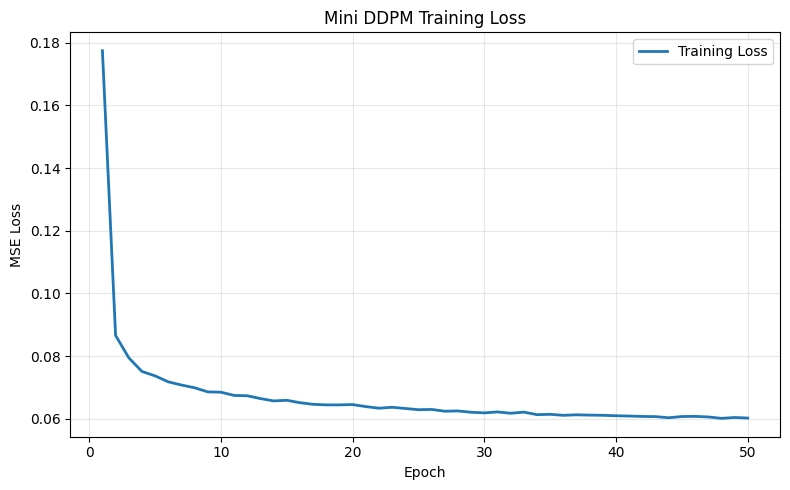

Initial loss: 0.1775
Final loss: 0.0602


In [10]:

plt.figure(figsize=(8, 5))

plt.plot(
    range(1, len(training_losses) + 1),
    training_losses,
    linewidth=2,
    label="Training Loss"
)

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("Mini DDPM Training Loss")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("Initial loss:", round(training_losses[0], 4))
print("Final loss:", round(training_losses[-1], 4))


### Training Observation

I trained the CNN for 50 epochs using MSE loss. The loss started at 0.1775 and decreased to 0.0602.

I noticed that the loss dropped quickly during the first few epochs. After that, it continued decreasing slowly and became more stable toward the end. This suggests that the model learned to predict the added noise better as training progressed.

## Part C: DDPM Sampling

After training the CNN, I will use it to generate new MNIST-like images.

Instead of starting with a real digit, I will begin with random Gaussian noise. At each timestep, the trained model predicts the noise in the current image, and I use that prediction to calculate the next, less noisy image.

I will repeat this process for all 100 diffusion steps and display the generated images.

In [11]:

# DDPM reverse sampling
@torch.no_grad()
def ddpm_sample(model, num_images=10):
    model.eval()

    # Start with random Gaussian noise
    x = torch.randn(num_images, 1, 28, 28, device=device)

    # Go backwards through all 100 timesteps
    for t in reversed(range(T)):
        t_batch = torch.full(
            (num_images,), t, device=device, dtype=torch.long
        )

        # Predict the noise at the current timestep
        predicted_noise = model(x, t_batch)

        alpha_t = alphas[t]
        alpha_bar_t = alpha_bars[t]
        beta_t = betas[t]

        # Calculate the reverse-process mean
        mean = (
            x - (beta_t / torch.sqrt(1 - alpha_bar_t))
            * predicted_noise
        ) / torch.sqrt(alpha_t)

        if t > 0:
            # Posterior variance for DDPM
            alpha_bar_prev = alpha_bars[t - 1]
            variance = (
                beta_t * (1 - alpha_bar_prev)
                / (1 - alpha_bar_t)
            )

            noise = torch.randn_like(x)
            x = mean + torch.sqrt(variance) * noise
        else:
            x = mean

    return x


# Generate 10 images
ddpm_images = ddpm_sample(model, num_images=10)

print("Generated images shape:", ddpm_images.shape)
print("DDPM sampling completed!")


Generated images shape: torch.Size([10, 1, 28, 28])
DDPM sampling completed!


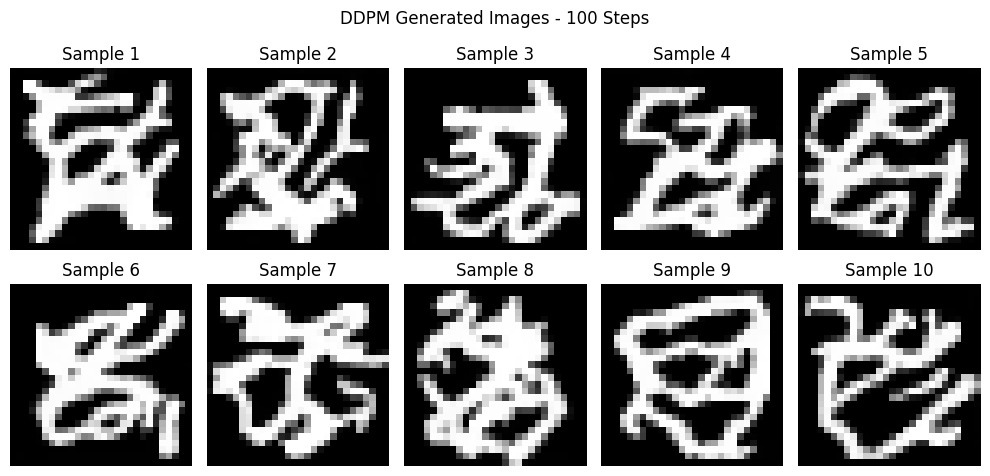

In [12]:

fig, axes = plt.subplots(2, 5, figsize=(10, 5))

for i, ax in enumerate(axes.flat):
    image = ddpm_images[i].squeeze().cpu().numpy()

    ax.imshow(image, cmap="gray", vmin=-1, vmax=1)
    ax.set_title(f"Sample {i + 1}")
    ax.axis("off")

plt.suptitle("DDPM Generated Images - 100 Steps")
plt.tight_layout()
plt.show()


### DDPM Sampling Observation

I generated 10 images using DDPM with 100 reverse sampling steps.

From the output, I can see that the model generated handwritten-like shapes, but most of them are not clearly recognizable as digits. Some images have overlapping strokes and distorted shapes.

Although the training loss decreased, the generated images are still not very clear. This shows that learning to predict noise does not always guarantee good image generation.

## Part D: DDIM Sampling

In this part, I will use DDIM sampling to generate images with fewer reverse steps.

I will use the same trained CNN, but instead of running all 100 steps, I will try 50 and 20 steps. I am using deterministic DDIM sampling with eta set to 0.

I will compare the images from DDPM and DDIM to see how reducing the number of sampling steps affects the generated results.

In [13]:

@torch.no_grad()
def ddim_sample(model, num_images=10, steps=50, eta=0.0,
                initial_noise=None):
    model.eval()

    # Start with Gaussian noise
    if initial_noise is None:
        x = torch.randn(num_images, 1, 28, 28, device=device)
    else:
        x = initial_noise.clone().to(device)

    # Select evenly spaced timesteps
    times = torch.linspace(
        0, T - 1, steps, device=device
    ).round().long()

    times = torch.unique(times).flip(0)

    for i, t in enumerate(times):
        t_index = int(t.item())

        t_batch = torch.full(
            (num_images,), t_index,
            device=device, dtype=torch.long
        )

        # Predict the noise
        predicted_noise = model(x, t_batch)

        alpha_bar_t = alpha_bars[t_index]

        # Estimate the original clean image
        x0_pred = (
            x - torch.sqrt(1 - alpha_bar_t) * predicted_noise
        ) / torch.sqrt(alpha_bar_t)

        # Get the previous selected timestep
        if i + 1 < len(times):
            prev_index = int(times[i + 1].item())
            alpha_bar_prev = alpha_bars[prev_index]
        else:
            alpha_bar_prev = torch.tensor(1.0, device=device)

        # DDIM update
        sigma = eta * torch.sqrt(
            (1 - alpha_bar_prev) / (1 - alpha_bar_t)
            * (1 - alpha_bar_t / alpha_bar_prev)
        )

        direction = torch.sqrt(
            torch.clamp(1 - alpha_bar_prev - sigma**2, min=0)
        ) * predicted_noise

        x = (
            torch.sqrt(alpha_bar_prev) * x0_pred
            + direction
            + sigma * torch.randn_like(x)
        )

    return x


In [14]:

import time

# Start both DDIM methods with the same random noise
initial_noise = torch.randn(10, 1, 28, 28, device=device)

# DDIM with 50 steps
start = time.perf_counter()

ddim_50_images = ddim_sample(
    model, num_images=10, steps=50,
    initial_noise=initial_noise
)

if device.type == "cuda":
    torch.cuda.synchronize()

ddim_50_time = time.perf_counter() - start

# DDIM with 20 steps
start = time.perf_counter()

ddim_20_images = ddim_sample(
    model, num_images=10, steps=20,
    initial_noise=initial_noise
)

if device.type == "cuda":
    torch.cuda.synchronize()

ddim_20_time = time.perf_counter() - start

print("DDIM 50 steps completed")
print("DDIM 20 steps completed")
print(f"DDIM 50 time: {ddim_50_time:.3f} seconds")
print(f"DDIM 20 time: {ddim_20_time:.3f} seconds")


DDIM 50 steps completed
DDIM 20 steps completed
DDIM 50 time: 0.265 seconds
DDIM 20 time: 0.050 seconds


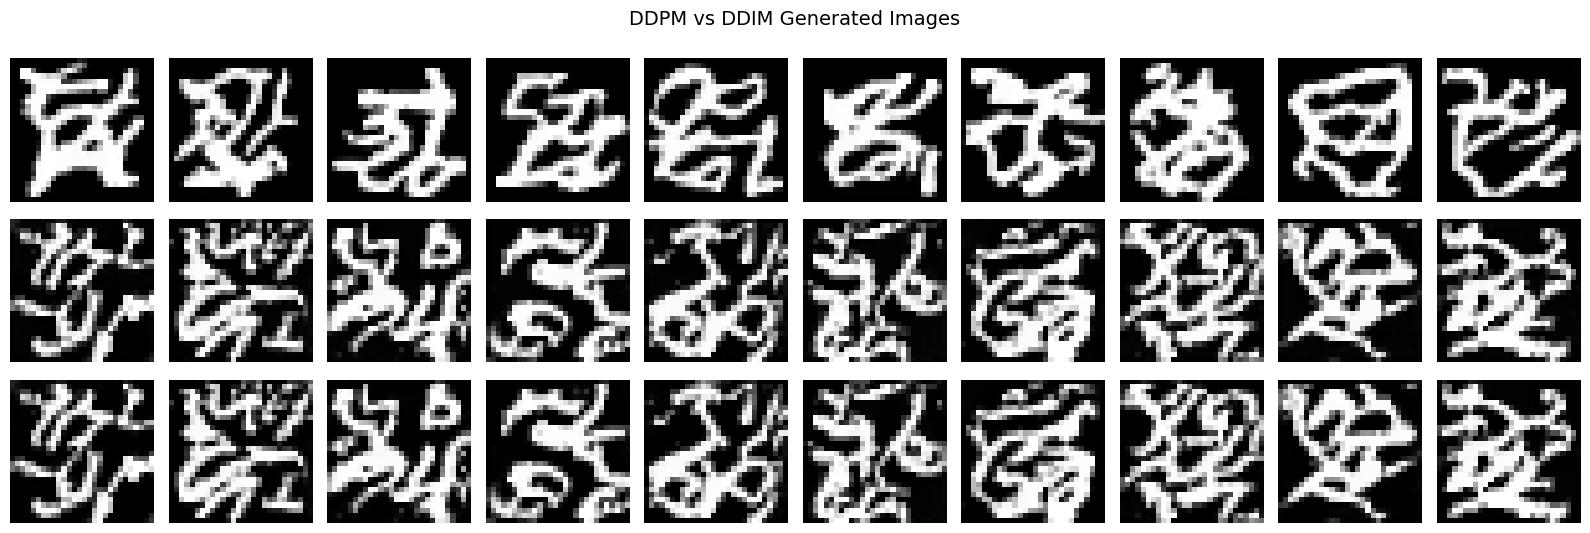

In [15]:

fig, axes = plt.subplots(3, 10, figsize=(16, 5.5))

methods = [
    ("DDPM - 100 steps", ddpm_images),
    ("DDIM - 50 steps", ddim_50_images),
    ("DDIM - 20 steps", ddim_20_images)
]

for row, (method_name, generated_images) in enumerate(methods):
    for col in range(10):
        image = generated_images[col].squeeze().cpu().numpy()

        axes[row, col].imshow(
            image, cmap="gray", vmin=-1, vmax=1
        )
        axes[row, col].axis("off")

    axes[row, 0].set_ylabel(
        method_name, fontsize=10, rotation=90,
        labelpad=15
    )

plt.suptitle("DDPM vs DDIM Generated Images", fontsize=14)
plt.tight_layout()
plt.show()


In [16]:

# Compare DDIM sampling time over multiple runs
def measure_ddim_time(steps, repeats=5):
    times = []

    # Warm up the GPU
    _ = ddim_sample(
        model, num_images=10, steps=steps,
        initial_noise=initial_noise
    )

    if device.type == "cuda":
        torch.cuda.synchronize()

    for _ in range(repeats):
        start = time.perf_counter()

        _ = ddim_sample(
            model, num_images=10, steps=steps,
            initial_noise=initial_noise
        )

        if device.type == "cuda":
            torch.cuda.synchronize()

        times.append(time.perf_counter() - start)

    return np.mean(times), np.std(times)


for steps in [50, 20]:
    avg, std = measure_ddim_time(steps)

    print(
        f"DDIM {steps} steps: "
        f"{avg:.4f} ± {std:.4f} seconds"
    )


DDIM 50 steps: 0.1172 ± 0.0158 seconds
DDIM 20 steps: 0.0428 ± 0.0015 seconds


### DDPM vs DDIM Comparison

I compared DDPM with 100 sampling steps and DDIM with 50 and 20 steps.

From the generated images, I noticed that all three methods produced handwritten-like shapes, but most were distorted and difficult to recognize as actual digits. The DDIM images from 50 and 20 steps looked almost identical.

### Sampling Time Comparison

To compare the speed, I measured the DDIM sampling time over five runs.

- **DDIM (50 steps):** 0.1172 ± 0.0158 seconds
- **DDIM (20 steps):** 0.0428 ± 0.0015 seconds

The 20-step DDIM method was about 2.74 times faster than the 50-step method.

### Final Observation

I noticed that reducing the number of DDIM sampling steps made image generation faster without causing a major visible difference in my results.

However, the generated digits were still unclear. Even though the CNN training loss decreased, the model did not produce clearly recognizable handwritten digits in most samples.

This experiment helped me understand that fewer sampling steps can improve generation speed, but image quality also depends on how well the model has learned the reverse diffusion process.